# XGBoost: previsão de compra (Revenue)

A avaliação usa o CSV convertido, o pré-processamento compartilhado e as mesmas cinco partições estratificadas dos demais modelos, com semente 42. As tabelas apresentam acurácia, precisão, recall e F1, considerando compra (`Revenue=1`) como classe positiva.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

raiz = Path.cwd().resolve()
if raiz.name == "script":
    raiz = raiz.parent
if not (raiz / "src" / "preprocessamento.py").is_file():
    raise FileNotFoundError("Execute o notebook a partir da raiz do projeto ou da pasta script.")
sys.path.insert(0, str(raiz / "src"))

from avaliacao import avaliar_modelo
from preprocessamento import (
    SEMENTE,
    carregar_dados,
    criar_particoes,
    criar_preprocessador,
    preparar_dados,
)

## Dados e partições

In [3]:
caminho = raiz / "dados" / "online_shoppers_convertido.csv"
dados = carregar_dados(caminho)
X, y = preparar_dados(dados)
particoes = criar_particoes(X, y)

print("Registros após remover duplicatas:", len(X))
print("Número de partições estratificadas:", len(particoes))
display(y.value_counts().sort_index().rename(index={0: "Sem compra", 1: "Compra"}).to_frame("quantidade"))

Registros após remover duplicatas: 12205
Número de partições estratificadas: 5


,quantidade
Revenue,
Sem compra,10297
Compra,1908


## Configurações e treinamento

Ambas as configurações usam 100 árvores, profundidade máxima 6 e taxa de aprendizado 0,1. A configuração base usa pesos iguais. A ponderada multiplica o peso da classe compra pela razão entre sessões sem compra e com compra no treino de cada fold. [Parâmetros do XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html#parameters-for-tree-booster)

O pré-processamento é ajustado no treino de cada fold. A saída é densa para preservar os zeros da codificação one-hot como valores válidos para as árvores. [FAQ do XGBoost](https://xgboost.readthedocs.io/en/stable/faq.html#why-do-i-see-different-results-with-sparse-and-dense-data)

In [4]:
class XGBClassifierPonderado(XGBClassifier):
    def fit(self, X, y, **kwargs):
        self.set_params(scale_pos_weight=(y == 0).sum() / (y == 1).sum())
        return super().fit(X, y, **kwargs)


parametros = {
    "objective": "binary:logistic",
    "tree_method": "hist",
    "n_estimators": 100,
    "max_depth": 6,
    "learning_rate": 0.1,
    "importance_type": "gain",
    "random_state": SEMENTE,
    "n_jobs": 4,
}
configuracoes = {
    "XGBoost base": XGBClassifier(**parametros),
    "XGBoost ponderado": XGBClassifierPonderado(**parametros),
}
modelos = {}
resultados = []
matrizes = {}

for nome, classificador in configuracoes.items():
    modelos[nome] = Pipeline([
        ("preprocessamento", criar_preprocessador().set_params(sparse_threshold=0.0)),
        ("modelo", classificador),
    ])
    metricas, matrizes[nome] = avaliar_modelo(modelos[nome], X, y, particoes)
    resultados.append(metricas.reset_index().assign(configuracao=nome))

## Métricas por fold e resumo

In [5]:
saida = raiz / "resultados"
saida.mkdir(exist_ok=True)

por_fold = pd.concat(resultados, ignore_index=True).rename(columns={
    "Fold": "fold",
    "Acurácia": "acuracia",
    "Precisão": "precisao",
    "Recall": "revocacao",
    "F1-score": "f1",
})
colunas_metricas = ["acuracia", "precisao", "revocacao", "f1"]
por_fold = por_fold[["configuracao", "fold", *colunas_metricas]]
resumo = por_fold.groupby("configuracao", sort=False)[colunas_metricas].agg(["mean", "std"])

print("Métricas por fold:")
display(por_fold.round(4))
print("Média e desvio padrão entre os cinco folds:")
display(resumo.round(4))

por_fold.to_csv(saida / "xgboost_metricas_por_fold.csv", index=False, encoding="utf-8-sig")
resumo.to_csv(saida / "xgboost_metricas_resumo.csv", encoding="utf-8-sig")

Métricas por fold:


,configuracao,fold,acuracia,precisao,revocacao,f1
0,XGBoost base,1,0.9041,0.7319,0.6089,0.6648
1,XGBoost base,2,0.9050,0.7508,0.5853,0.6578
2,XGBoost base,3,0.8980,0.7085,0.5916,0.6448
3,XGBoost base,4,0.9009,0.7083,0.6230,0.6630
4,XGBoost base,5,0.9021,0.7227,0.6073,0.6600
5,XGBoost ponderado,1,0.8697,0.5558,0.8241,0.6638
6,XGBoost ponderado,2,0.8771,0.5763,0.8031,0.6711
7,XGBoost ponderado,3,0.8783,0.5788,0.8168,0.6775
8,XGBoost ponderado,4,0.8632,0.5424,0.8037,0.6477
9,XGBoost ponderado,5,0.8738,0.5665,0.8246,0.6716


Média e desvio padrão entre os cinco folds:


acuracia         precisao         revocacao              f1  \
                      mean     std     mean     std      mean     std    mean   
configuracao                                                                    
XGBoost base        0.9020  0.0028   0.7244  0.0178    0.6032  0.0150  0.6581   
XGBoost ponderado   0.8724  0.0062   0.5640  0.0151    0.8145  0.0106  0.6663   

                           
                      std  
configuracao               
XGBoost base       0.0079  
XGBoost ponderado  0.0115

## Matrizes de confusão

Cada matriz agrega as previsões feitas nas partes de validação dos cinco folds.

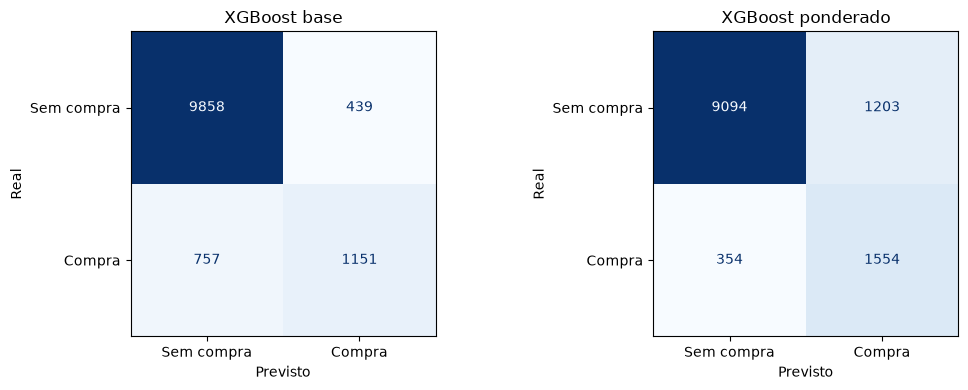

In [6]:
fig, eixos = plt.subplots(1, len(matrizes), figsize=(5.5 * len(matrizes), 4), squeeze=False)

for eixo, (nome, matriz) in zip(eixos[0], matrizes.items()):
    ConfusionMatrixDisplay(matriz, display_labels=["Sem compra", "Compra"]).plot(
        ax=eixo, cmap="Blues", colorbar=False, values_format="d"
    )
    eixo.set_title(nome)
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")

    sufixo = nome.lower().replace(" ", "_")
    pd.DataFrame(
        matriz,
        index=["real_sem_compra", "real_compra"],
        columns=["previsto_sem_compra", "previsto_compra"],
    ).to_csv(saida / f"matriz_{sufixo}.csv", encoding="utf-8-sig")

fig.tight_layout()
fig.savefig(saida / "matrizes_confusao_xgboost.png", dpi=300)
plt.show()

## Importância das variáveis

Para visualizar as dez variáveis transformadas com maior importância por ganho, a configuração com maior F1 médio é ajustada em toda a base preparada. As métricas e as matrizes de confusão vêm das previsões feitas na validação cruzada.

Configuração com maior F1 médio: XGBoost ponderado


,ganho
numericas__PageValues,0.2324
categoricas__Month_11,0.1039
categoricas__Month_5,0.0587
categoricas__Month_3,0.0530
categoricas__VisitorType_1,0.0340
categoricas__TrafficType_3,0.0167
categoricas__TrafficType_13,0.0160
numericas__ProductRelated_Duration,0.0158
categoricas__Month_9,0.0156
numericas__BounceRates,0.0152


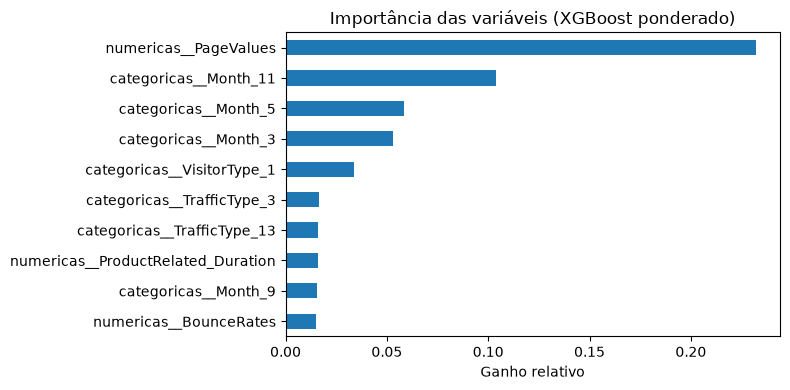

In [7]:
nome_final = resumo[("f1", "mean")].idxmax()
modelo_final = clone(modelos[nome_final]).fit(X, y)

nomes = modelo_final.named_steps["preprocessamento"].get_feature_names_out()
importancias = pd.Series(
    modelo_final.named_steps["modelo"].feature_importances_,
    index=nomes,
    name="ganho",
)
top_10 = importancias.nlargest(10)
print("Configuração com maior F1 médio:", nome_final)
display(top_10.round(4).to_frame())

eixo = top_10.iloc[::-1].plot.barh(figsize=(8, 4))
eixo.set_title(f"Importância das variáveis ({nome_final})")
eixo.set_xlabel("Ganho relativo")
fig = eixo.get_figure()
fig.tight_layout()
fig.savefig(saida / "importancia_variaveis_xgboost.png", dpi=300)
plt.show()